## Imports

In [1]:
%matplotlib inline
from init_df import body_df, title_df, embeddings_subreddits_df, embeddings_users_df
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Check Data
body_df
title_df
embeddings_subreddits_df

,SUBREDDIT,emb_0,emb_1,emb_2,emb_3,emb_4,emb_5,emb_6,emb_7,emb_8,...,emb_290,emb_291,emb_292,emb_293,emb_294,emb_295,emb_296,emb_297,emb_298,emb_299
0,spiders,0.158972,0.285813,0.226329,-0.183338,-0.163159,-0.188910,0.422705,0.168602,0.178193,...,-0.025041,0.184655,0.111942,-1.125799,0.223129,-0.387323,-0.234882,-0.252297,-0.054315,0.500009
1,askreddit,-0.499114,0.323983,-0.424809,-0.222705,-0.327201,0.412856,1.040088,0.996697,-1.256240,...,0.072151,0.226658,0.535705,0.039861,-0.027087,-0.239952,0.554510,0.676439,-0.328846,0.941547
2,globaloffensivetrade,-0.023145,-1.199374,1.661484,-1.025296,1.424670,-1.179507,-1.035703,0.329301,-0.567272,...,2.998430,-1.235703,-0.326850,4.381238,-1.965378,-2.369674,-0.615389,2.010601,-0.919314,-2.149625
3,fireteams,2.492506,-2.529917,-0.448484,-3.543441,-0.586122,-0.101517,1.837567,-0.215715,-2.460388,...,-1.875214,0.969291,0.497958,2.941132,2.423561,1.315691,-0.959618,0.151845,-0.852492,-0.467526
4,funny,-0.819370,-0.865261,0.301753,0.018787,0.201029,0.070462,0.903895,1.038460,-0.306950,...,1.364194,0.830233,-0.137822,-2.204667,-0.162008,0.390291,-0.556404,0.322684,0.641634,1.320716
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51273,33rd,-0.000076,-0.001643,-0.002896,0.000581,-0.003509,-0.000827,0.002095,0.000123,0.004370,...,-0.001570,-0.002246,0.003491,-0.004310,0.001598,0.005168,-0.001156,0.001575,-0.001938,0.001594
51274,bestofvic2015,-0.000203,0.012698,-0.007575,0.006486,-0.001693,0.004743,-0.002401,0.000121,0.001600,...,0.001392,0.001258,0.002970,-0.014106,-0.002713,-0.008648,0.003660,-0.005755,-0.001790,-0.001313
51275,aberystwyth,-0.001563,0.004733,-0.000082,-0.000982,-0.001511,0.001285,0.002187,0.002967,0.000660,...,0.002213,0.000520,-0.000564,-0.010018,0.002507,-0.000651,0.004169,-0.004672,0.002371,0.001073
51276,mail_forwarding,0.009269,0.024779,-0.017018,-0.007228,0.002351,0.003462,-0.008446,0.004544,0.022505,...,-0.002591,0.003482,0.001042,-0.002796,0.010739,-0.009148,0.000363,-0.003144,0.001945,-0.017272


### Negativity instigators

Top 15 most negative communities:

                   neg_posts_made  neg_posts_received  avg_vader_neg_sent  \
subredditdrama             8987.0               814.0            0.195356   
bestof                     3464.0               253.0            0.212973   
drama                      2690.0               275.0            0.210438   
circlebroke2               1769.0                55.0            0.260777   
shitpost                   1308.0                67.0            0.264505   
botsrights                  735.0                 9.0            0.333561   
shitstatistssay             982.0                61.0            0.231008   
shitredditsays             1036.0               254.0            0.197575   
srssucks                    782.0                94.0            0.235207   
gamingcirclejerk            625.0                19.0            0.256501   
fitnesscirclejerk           603.0                37.0            0.249458   
shitamericanssay            792.0        

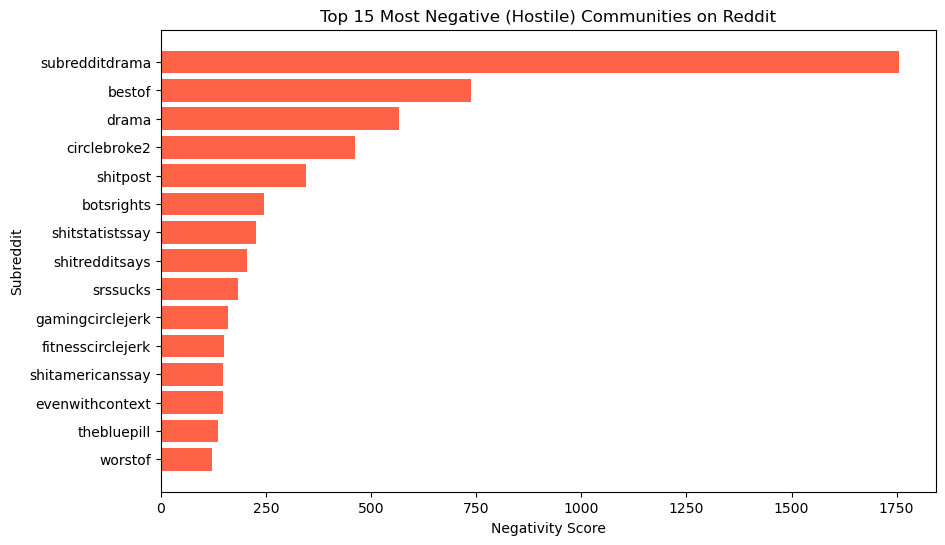

In [3]:
# --- Step 1: Combine both datasets (body and title) ---
combined_df = pd.concat([body_df, title_df], ignore_index=True)

# --- Step 2: Filter negative interactions ---
# Assuming POST_LABEL = 1 means positive, -1 means negative
negative_df = combined_df[combined_df["LINK_SENTIMENT"] == -1]

# --- Step 3: Compute subreddit-level negativity metrics ---
# Count number of negative posts made BY each subreddit
neg_sent_by = negative_df.groupby("SOURCE_SUBREDDIT").size().rename("neg_posts_made")

# Count number of negative posts RECEIVED by each subreddit
neg_sent_received = negative_df.groupby("TARGET_SUBREDDIT").size().rename("neg_posts_received")

# Merge them into one DataFrame
negativity_stats = pd.concat([neg_sent_by, neg_sent_received], axis=1).fillna(0)

# --- Step 4: Compute additional indicators of hostility ---
# Average VADER negative sentiment by subreddit
avg_vader_neg = (
    negative_df.groupby("SOURCE_SUBREDDIT")["Negative sentiment calculated by VADER"]
    .mean()
    .rename("avg_vader_neg_sent")
)

# Merge this too
negativity_stats = negativity_stats.merge(avg_vader_neg, left_index=True, right_index=True, how="left").fillna(0)

# --- Step 5: Sort by "most hostile" communities ---
negativity_stats["negativity_score"] = (
    negativity_stats["neg_posts_made"] * negativity_stats["avg_vader_neg_sent"]
)
negativity_stats = negativity_stats.sort_values("negativity_score", ascending=False)

# --- Step 6: Display top offenders ---
print("Top 15 most negative communities:\n")
print(negativity_stats.head(15))

# --- Visualization ---
import matplotlib.pyplot as plt

top15 = negativity_stats.head(15)
plt.figure(figsize=(10, 6))
plt.barh(top15.index, top15["negativity_score"], color="tomato")
plt.xlabel("Negativity Score")
plt.ylabel("Subreddit")
plt.title("Top 15 Most Negative (Hostile) Communities on Reddit")
plt.gca().invert_yaxis()
plt.show()


### Negativity "sinks"

Top 15 subreddits that absorb negativity (end of negativity chains):

                  neg_in  neg_out  sink_score
dataisbeautiful    226.0      0.0         1.0
documentaries      198.0      0.0         1.0
oldschoolcool      151.0      0.0         1.0
historyporn        106.0      0.0         1.0
whowouldwin        104.0      0.0         1.0
me_irl              77.0      0.0         1.0
offbeat             71.0      0.0         1.0
mapporn             65.0      0.0         1.0
whatcouldgowrong    60.0      0.0         1.0
starterpacks        54.0      0.0         1.0
youtubehaiku        53.0      0.0         1.0
art                 51.0      0.0         1.0
standupshots        48.0      0.0         1.0
polandball          41.0      0.0         1.0
sf4                 41.0      0.0         1.0


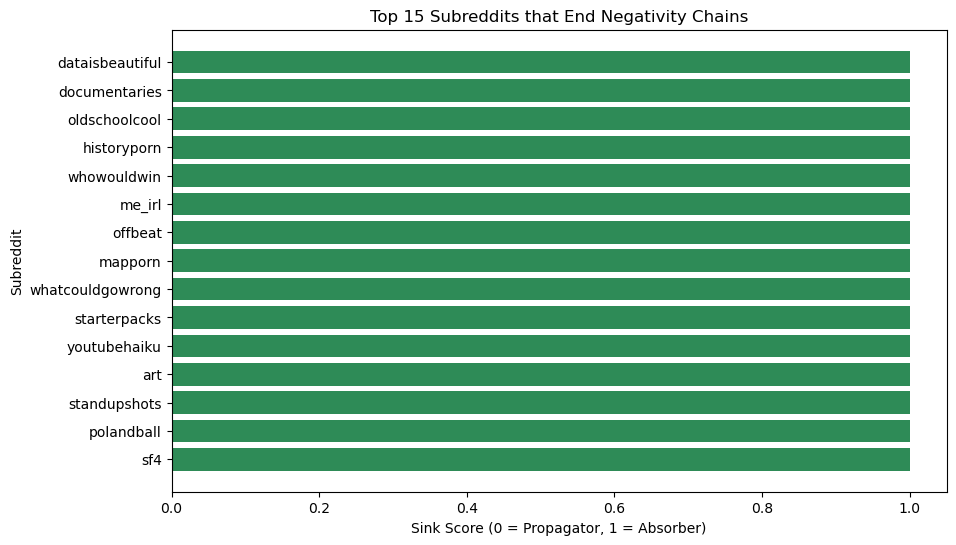

In [4]:
# 3. Count how many negative posts each subreddit SENDS and RECEIVES
neg_sent = negative_df.groupby("SOURCE_SUBREDDIT").size().rename("neg_out")
neg_received = negative_df.groupby("TARGET_SUBREDDIT").size().rename("neg_in")

# 4. Merge and compute sink metrics
neg_flow = pd.concat([neg_sent, neg_received], axis=1).fillna(0)

# Sink score: closer to 1 = absorbs negativity, closer to 0 = spreads it
neg_flow["sink_score"] = neg_flow["neg_in"] / (neg_flow["neg_in"] + neg_flow["neg_out"] + 1e-6)

# Optional: total volume of negative interactions
neg_flow["total_negativity"] = neg_flow["neg_in"] + neg_flow["neg_out"]

# 5. Filter out communities with very low activity (to reduce noise)
active_communities = neg_flow[neg_flow["total_negativity"] > 10]

# 6. Sort by sink score
sink_communities = active_communities.sort_values("sink_score", ascending=False)

# 7. Display results
print("Top 15 subreddits that absorb negativity (end of negativity chains):\n")
print(sink_communities.head(15)[["neg_in", "neg_out", "sink_score"]])

# 8. Visualization
plt.figure(figsize=(10, 6))
top15 = sink_communities.head(15)
plt.barh(top15.index, top15["sink_score"], color="seagreen")
plt.xlabel("Sink Score (0 = Propagator, 1 = Absorber)")
plt.ylabel("Subreddit")
plt.title("Top 15 Subreddits that End Negativity Chains")
plt.gca().invert_yaxis()
plt.show()

### Most negatively targeted (proportionnaly)

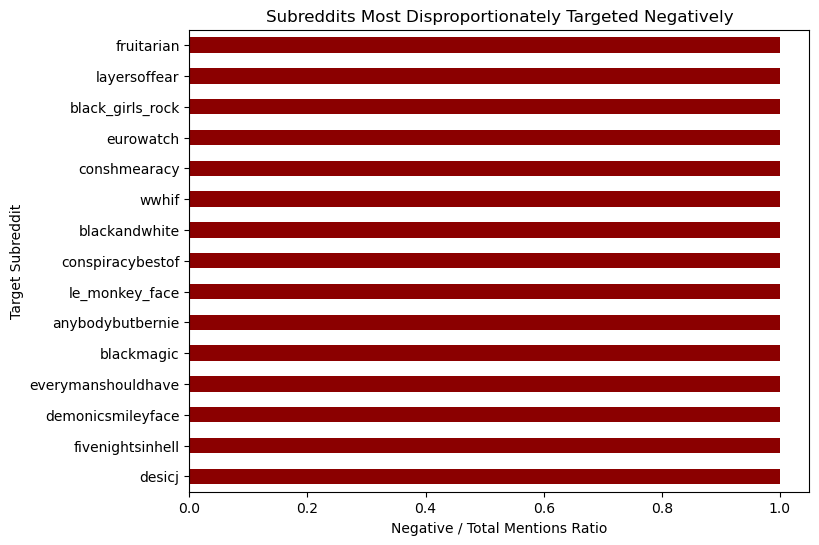

🔴 Subreddits most disproportionately targeted negatively:


LINK_SENTIMENT,negative,total_targets,neg_ratio
TARGET_SUBREDDIT,,,
fruitarian,1,1,1.0
layersoffear,1,1,1.0
black_girls_rock,1,1,1.0
eurowatch,2,2,1.0
conshmearacy,1,1,1.0
wwhif,1,1,1.0
blackandwhite,1,1,1.0
conspiracybestof,1,1,1.0
le_monkey_face,1,1,1.0


In [5]:
# Combine body and title datasets
combined_df = pd.concat([body_df, title_df], ignore_index=True)

# --- 1️⃣ Count how often each subreddit is targeted ---
target_counts = (
    combined_df.groupby("TARGET_SUBREDDIT")["LINK_SENTIMENT"]
    .value_counts()
    .unstack(fill_value=0)
    .rename(columns={-1: "negative", 1: "positive"})
)

# Add a total column
target_counts["total_targets"] = target_counts.sum(axis=1)

# --- 2️⃣ Rank subreddits ---
most_targeted_overall = target_counts.sort_values("total_targets", ascending=False).head(15)
most_targeted_negative = target_counts.sort_values("negative", ascending=False).head(15)
most_targeted_positive = target_counts.sort_values("positive", ascending=False).head(15)

target_counts["neg_ratio"] = target_counts["negative"] / target_counts["total_targets"]

# Sort by negativity ratio
most_negatively_targeted_ratio = target_counts.sort_values("neg_ratio", ascending=False).head(15)

top_n = 15
most_negatively_targeted_ratio.head(top_n).plot(
    y="neg_ratio",
    kind="barh",
    color="darkred",
    figsize=(8,6),
    legend=False
)
plt.gca().invert_yaxis()
plt.title("Subreddits Most Disproportionately Targeted Negatively")
plt.xlabel("Negative / Total Mentions Ratio")
plt.ylabel("Target Subreddit")
plt.show()

print("🔴 Subreddits most disproportionately targeted negatively:")
display(most_negatively_targeted_ratio[["negative", "total_targets", "neg_ratio"]])


## Investigating negativity structure

In [6]:
import networkx as nx

# Build a directed graph of negative interactions
G_neg = nx.from_pandas_edgelist(
    negative_df,
    source="SOURCE_SUBREDDIT",
    target="TARGET_SUBREDDIT",
    create_using=nx.DiGraph()
)

print(f"Number of subreddits (nodes): {G_neg.number_of_nodes()}")
print(f"Number of negative links (edges): {G_neg.number_of_edges()}")

Number of subreddits (nodes): 12069
Number of negative links (edges): 41170


### Cascades

In [7]:
# Compute lengths of the largest strongly connected components
components = sorted(nx.strongly_connected_components(G_neg), key=len, reverse=True)
largest_comp = G_neg.subgraph(components[0])

avg_path_length = nx.average_shortest_path_length(largest_comp)
print(f"Average path length in largest negative component: {avg_path_length:.2f}")

Average path length in largest negative component: 3.96


In [8]:
cascade_sizes = []
for node in G_neg.nodes():
    reachable = nx.descendants(G_neg, node)
    cascade_sizes.append(len(reachable))

import numpy as np
print(f"Average cascade size: {np.mean(cascade_sizes):.2f}")

Average cascade size: 3461.29


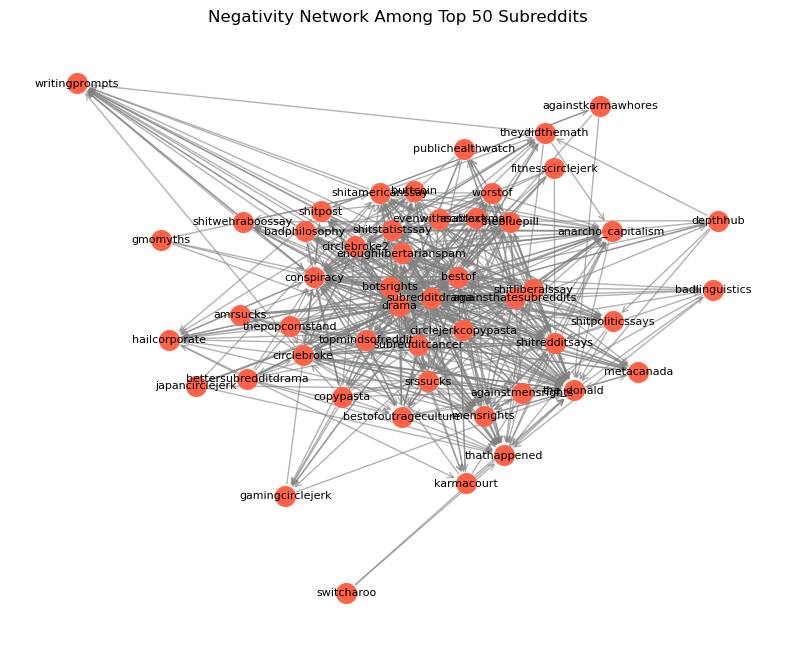

In [9]:
# Take a subgraph of the top 50 most active subreddits in negativity
activity = negative_df["SOURCE_SUBREDDIT"].value_counts().head(50).index
G_sub = G_neg.subgraph(activity)

plt.figure(figsize=(10, 8))
pos = nx.spring_layout(G_sub, k=0.5, seed=42)
nx.draw_networkx_nodes(G_sub, pos, node_size=200, node_color="tomato")
nx.draw_networkx_edges(G_sub, pos, arrowstyle="->", arrowsize=10, edge_color="gray", alpha=0.6)
nx.draw_networkx_labels(G_sub, pos, font_size=8)
plt.title("Negativity Network Among Top 50 Subreddits")
plt.axis("off")
plt.show()  

In [10]:
# Initialize directed graph
G = nx.DiGraph()

# Add nodes (subreddits)
subreddits = pd.unique(combined_df[["SOURCE_SUBREDDIT", "TARGET_SUBREDDIT"]].values.ravel())
G.add_nodes_from(subreddits)

# Add edges with sign as attribute
for _, row in combined_df.iterrows():
    G.add_edge(
        row["SOURCE_SUBREDDIT"], 
        row["TARGET_SUBREDDIT"], 
        sign=row["LINK_SENTIMENT"]  # +1 or -1
    )

plt.figure(figsize=(12, 12))

# Compute layout
pos = nx.spring_layout(G, k=0.15, iterations=20, seed=42)

# Positive interactions
G_pos = nx.DiGraph([(u, v) for u, v, d in G.edges(data=True) if d['sign'] == 1])

# Negative interactions
G_neg = nx.DiGraph([(u, v) for u, v, d in G.edges(data=True) if d['sign'] == -1])

# Draw edges: red for negative, green for positive
nx.draw_networkx_edges(G, pos, edgelist=G_neg.edges(), edge_color='red', alpha=0.3)
nx.draw_networkx_edges(G, pos, edgelist=G_pos.edges(), edge_color='green', alpha=0.2)

top_subs = combined_df['SOURCE_SUBREDDIT'].value_counts().head(100).index
G_small = G.subgraph(top_subs).copy()

# Draw nodes
nx.draw_networkx_nodes(G_small, pos, node_size=10, node_color='blue', alpha=0.7)

plt.title("Reddit Subreddit Interaction Network\nGreen: positive, Red: negative")
plt.axis('off')
plt.show()

KeyboardInterrupt: 

<Figure size 1200x1200 with 0 Axes>

### Temporal animation

41 months contain negative edges.


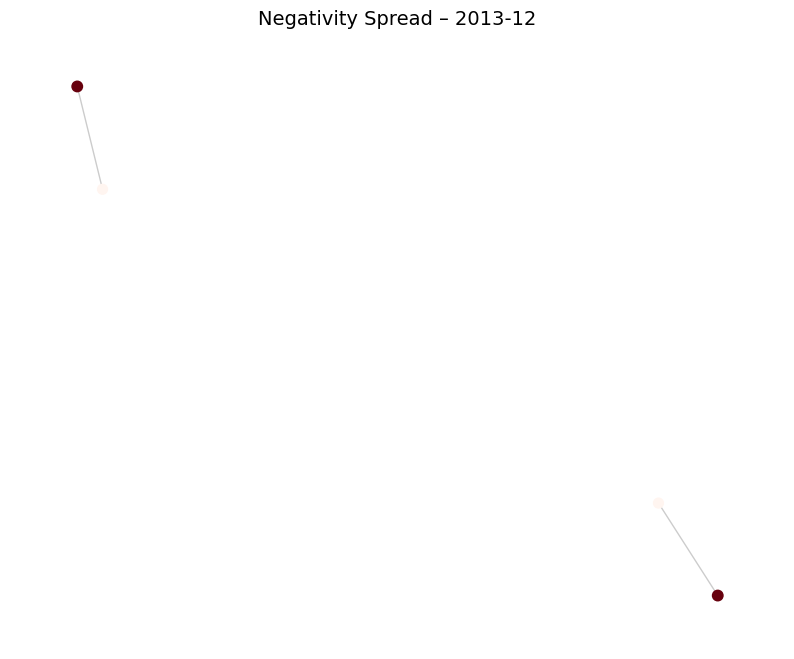

In [11]:
from matplotlib.animation import FuncAnimation

# --- Combine and filter ---
neg_df = combined_df[combined_df["LINK_SENTIMENT"] == -1].copy()
neg_df["TIMESTAMP"] = pd.to_datetime(neg_df["TIMESTAMP"], errors="coerce")
neg_df["month"] = neg_df["TIMESTAMP"].dt.to_period("M")

# Keep only non-empty months
months = sorted(neg_df["month"].dropna().unique())
months = [m for m in months if neg_df[neg_df["month"] == m].shape[0] > 0]
print(f"{len(months)} months contain negative edges.")

# --- Setup figure ---
fig, ax = plt.subplots(figsize=(10, 8))
plt.title("Negativity Network Evolution")

def update(frame):
    ax.clear()
    current_month = months[frame]
    sub_df = neg_df[neg_df["month"] == current_month]
    
    # Build the monthly graph
    G = nx.from_pandas_edgelist(
        sub_df,
        source="SOURCE_SUBREDDIT",
        target="TARGET_SUBREDDIT",
        create_using=nx.DiGraph()
    )
    
    if len(G) == 0:
        ax.text(0.5, 0.5, f"No negativity in {current_month}", ha="center", va="center")
        ax.axis("off")
        return
    
    # Dynamic layout (since different subgraphs per month)
    pos = nx.spring_layout(G, seed=42, k=0.5)
    
    # Compute metrics for visualization
    indeg = dict(G.in_degree())
    node_color = list(indeg.values())
    node_size = [50 + 10 * np.log1p(v) for v in indeg.values()]  # scaled by log
    
    # Draw graph
    nx.draw_networkx_edges(G, pos, edge_color="gray", alpha=0.4, arrows=False)
    nx.draw_networkx_nodes(G, pos, node_color=node_color, cmap="Reds", node_size=node_size)
    
    ax.set_title(f"Negativity Spread – {current_month}", fontsize=14)
    ax.axis("off")

# --- Animate ---
ani = FuncAnimation(fig, update, frames=len(months), interval=400, repeat=False)

ani.save("negativity_over_time.gif", writer="pillow")

## Periodicity check

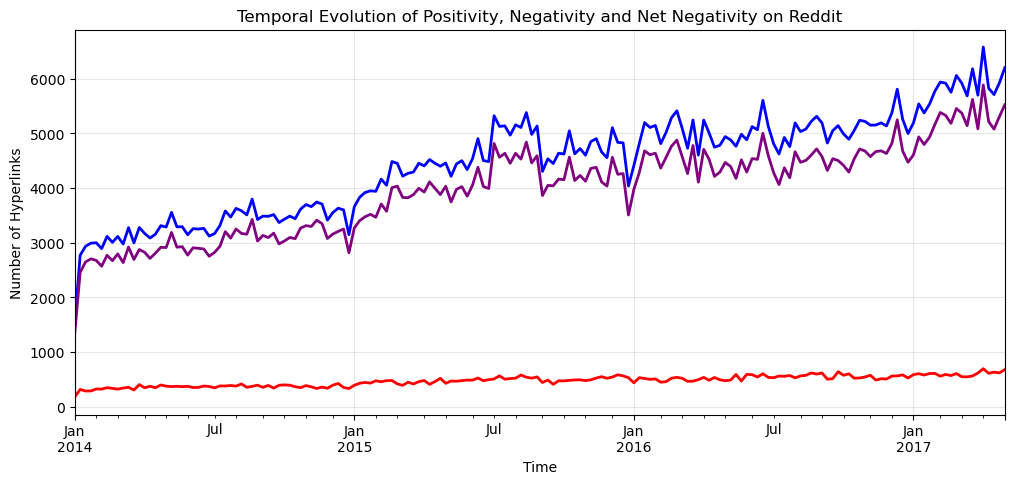

In [12]:
combined_df["TIMESTAMP"] = pd.to_datetime(combined_df["TIMESTAMP"], errors="coerce")

# Focus only on negative posts
neg_df = combined_df[combined_df["LINK_SENTIMENT"] == -1].copy()
pos_df = combined_df[combined_df["LINK_SENTIMENT"] == 1].copy()

# Aggregate monthly (or weekly) count of negativity
neg_time_series = (
    neg_df.groupby(pd.Grouper(key="TIMESTAMP", freq="W"))
    .size()
    .rename("neg_count")
)

pos_time_series = (
    pos_df.groupby(pd.Grouper(key="TIMESTAMP", freq="W"))
    .size()
    .rename("pos_count")
)

avg_time_series = pos_time_series - neg_time_series

# Plot
plt.figure(figsize=(12, 5))
pos_time_series.plot(color="blue", linewidth=2)
neg_time_series.plot(color="red", linewidth=2)
avg_time_series.plot(color="purple", linewidth=2)
plt.title("Temporal Evolution of Positivity, Negativity and Net Negativity on Reddit")
plt.xlabel("Time")
plt.ylabel("Number of Hyperlinks")
plt.grid(alpha=0.3)
plt.legend
plt.show()

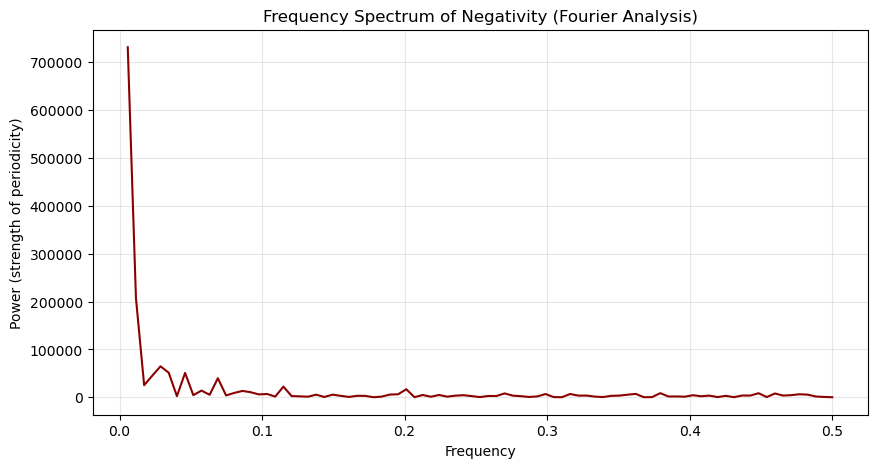

In [13]:
import numpy as np
from scipy.signal import periodogram

# Fourier transform
freqs, power = periodogram(neg_time_series, fs=1)  # fs=1 = 1 sample per month

plt.figure(figsize=(10, 5))
plt.plot(freqs[1:], power[1:], color="darkred")
plt.title("Frequency Spectrum of Negativity (Fourier Analysis)")
plt.xlabel("Frequency")
plt.ylabel("Power (strength of periodicity)")
plt.grid(alpha=0.3)
plt.show()


Top 10 subreddits with strongest negativity periodicity:
subredditdrama             periodicity power = 811.62
bettersubredditdrama       periodicity power = 649.93
drama                      periodicity power = 220.02
circlebroke2               periodicity power = 162.77
bestof                     periodicity power = 161.06
peoplewhosayheck           periodicity power = 139.27
subreddit_stats            periodicity power = 80.74
shitpost                   periodicity power = 72.77
the_donald                 periodicity power = 61.09
evenwithcontext            periodicity power = 56.24


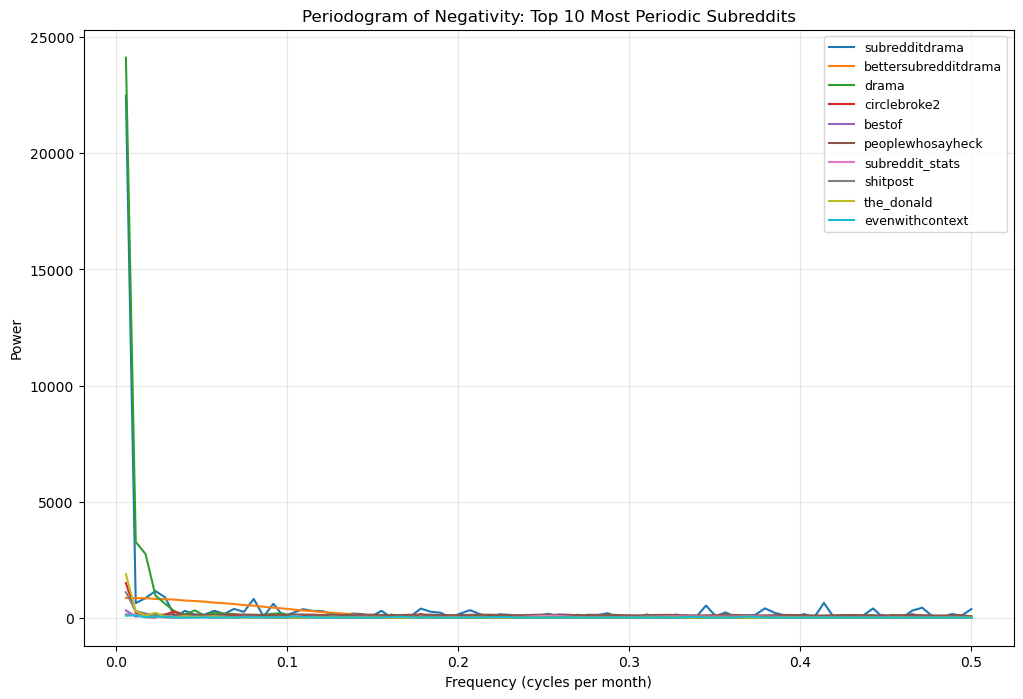

In [17]:
neg_by_sub = (
    neg_df.groupby(["SOURCE_SUBREDDIT", pd.Grouper(key="TIMESTAMP", freq="W")])
    .size()
    .unstack(fill_value=0)
)

# Compute Fourier transform for each subreddit
from scipy.signal import periodogram

periodic_strength = {}
for sub in neg_by_sub.index:
    freqs, power = periodogram(neg_by_sub.loc[sub].values, fs=1)
    periodic_strength[sub] = power[10:].max()  # max power excluding DC component

top_periodic = sorted(periodic_strength.items(), key=lambda x: x[1], reverse=True)[:10]
print("Top 10 subreddits with strongest negativity periodicity:")
for sub, p in top_periodic:
    print(f"{sub:25s}  periodicity power = {p:.2f}")

plt.figure(figsize=(12, 8))

for sub, _ in top_periodic:
    y = neg_by_sub.loc[sub].values
    freqs, power = periodogram(y, fs=1)
    plt.plot(freqs[1:], power[1:], label=sub)  # skip DC component

plt.xlabel("Frequency (cycles per month)")
plt.ylabel("Power")
plt.title("Periodogram of Negativity: Top 10 Most Periodic Subreddits")
plt.legend(loc='upper right', fontsize=9)
plt.grid(alpha=0.3)
plt.show()

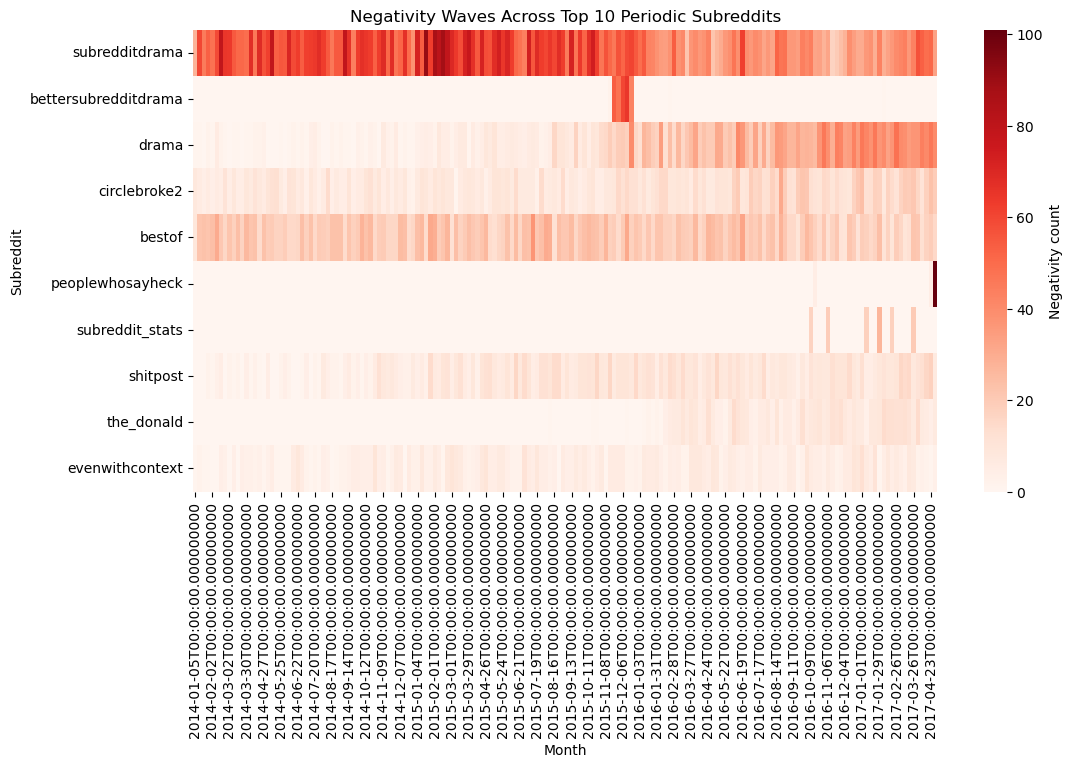

In [18]:
top_subs = [s for s, _ in top_periodic[:10]]
plt.figure(figsize=(12, 6))
sns.heatmap(neg_by_sub.loc[top_subs], cmap="Reds", cbar_kws={"label": "Negativity count"})
plt.title("Negativity Waves Across Top 10 Periodic Subreddits")
plt.xlabel("Month")
plt.ylabel("Subreddit")
plt.show()


# Playing with embeddings

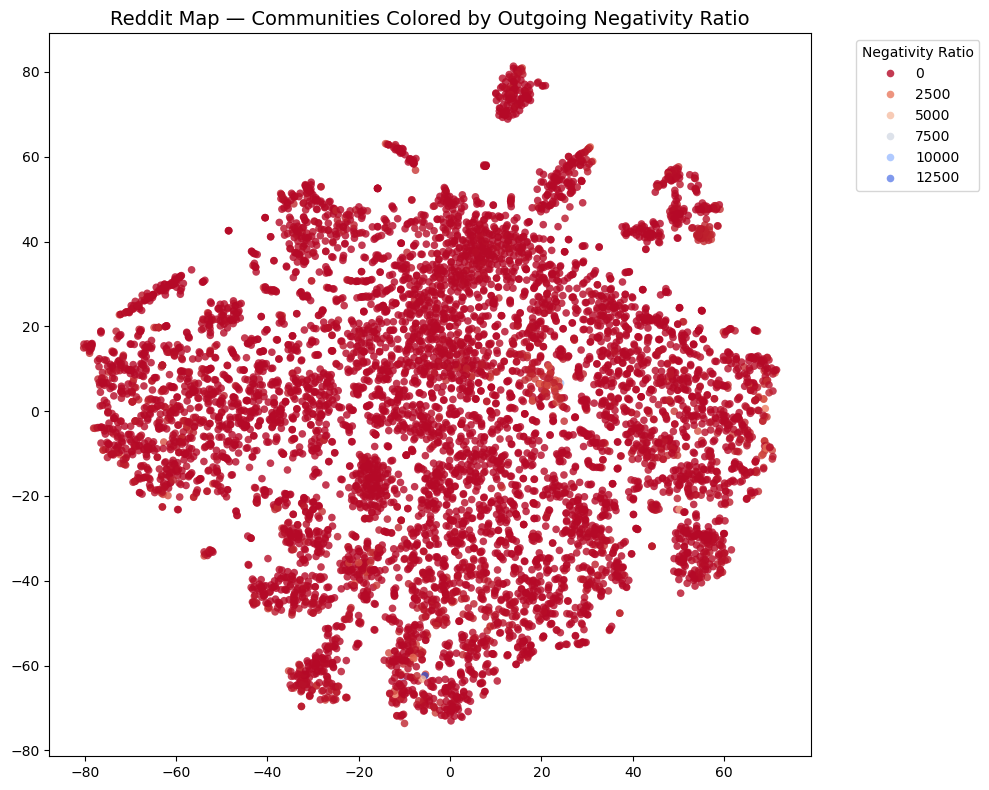

In [16]:
from sklearn.manifold import TSNE

# === Combine body and title datasets ===
combined_df = pd.concat([body_df, title_df], ignore_index=True)

# === Compute negativity ratio for outgoing posts (source subreddit behavior) ===
source_counts = (
    combined_df.groupby("SOURCE_SUBREDDIT")["LINK_SENTIMENT"]
    .value_counts()
    .unstack(fill_value=0)
    .rename(columns={-1: "negative", 1: "positive"})
)

source_counts["total_posts"] = source_counts.sum(axis=1)
source_counts = source_counts[source_counts["total_posts"] > 10]  # filter very small subs
source_counts["neg_ratio"] = source_counts["positive"] - source_counts["negative"]

# === Merge with embeddings dataframe ===
merged = embeddings_subreddits_df.merge(
    source_counts["neg_ratio"], left_on="SUBREDDIT", right_index=True, how="inner"
).dropna()

embedding_columns = [col for col in embeddings_subreddits_df.columns if col.startswith("emb_")]

# === Dimensionality reduction with t-SNE ===
tsne = TSNE(n_components=2, perplexity=30, learning_rate=200, random_state=42)
tsne_coords = tsne.fit_transform(merged[embedding_columns])
merged["x"] = tsne_coords[:, 0]
merged["y"] = tsne_coords[:, 1]

# === Plot ===
plt.figure(figsize=(10, 8))
sns.scatterplot(
    data=merged,
    x="x",
    y="y",
    hue="neg_ratio",
    palette="coolwarm_r",  # red = more negative
    s=30,
    linewidth=0,
    alpha=0.8,
)
plt.title("Reddit Map — Communities Colored by Outgoing Negativity Ratio", fontsize=14)
plt.xlabel("")
plt.ylabel("")
plt.legend(title="Negativity Ratio", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()